In [ ]:
# from google.colab import drive

# drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

DATASET_DIR = Path("/content/drive/MyDrive/datasets/DocLayNet-small")
DATASET_DIR.mkdir(parents=True, exist_ok=True)

### Authenticating with Hugging Face using Colab Secrets

Make sure you have added your Hugging Face Token to the Colab Secrets manager (🔑 icon on the left) with the key name `HF_TOKEN`.

In [ ]:
# import os
# from google.colab import userdata

# try:
#     # Retrieve token securely from Colab Secrets
#     os.environ["HF_TOKEN"] = userdata.get('HF_TOKEN')
#     print("Hugging Face token successfully configured from Colab Secrets!")
# except Exception as e:
#     print("Could not retrieve HF_TOKEN from Secrets. Please make sure it is added and access is granted.")
#     print("Error details:", e)

Hugging Face token successfully configured from Colab Secrets!


### Alternative Method: Direct Login Prompt

If you prefer to manually log in each session, you can use the official `huggingface_hub` interactive login instead:

In [ ]:
# # !pip install -q huggingface_hub
# from huggingface_hub import login

# # This will prompt you to enter your token directly in a text field
# login()

In [ ]:
! pip install -q "datasets==3.6.0"

In [1]:
# from datasets import load_dataset

# # Bypassing the faulty local builder script by loading the pre-generated parquet files directly
# dataset = load_dataset(
#     "pierreguillou/DocLayNet-small",
#     data_files={
#         "train": "data/train-*.parquet",
#         "validation": "data/validation-*.parquet",
#         "test": "data/test-*.parquet"
#     },
#     cache_dir=str(DATASET_DIR / "cache")
# )

In [ ]:
# from google.colab import drive
# drive.mount("/content/drive")

# from pathlib import Path
# import requests
# import zipfile

# DATASET_DIR = Path("/content/drive/MyDrive/datasets/DocLayNet-small")
# ZIP_PATH = DATASET_DIR / "dataset_small.zip"

# DATASET_DIR.mkdir(parents=True, exist_ok=True)

# URL = (
#     "https://huggingface.co/datasets/"
#     "pierreguillou/DocLayNet-small/resolve/main/data/dataset_small.zip"
# )

# # Download
# if not ZIP_PATH.exists():
#     response = requests.get(URL, stream=True)
#     response.raise_for_status()

#     with open(ZIP_PATH, "wb") as f:
#         for chunk in response.iter_content(chunk_size=1024 * 1024):
#             if chunk:
#                 f.write(chunk)

# print("Download completed!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Download completed!


In [ ]:
# with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
#     zip_ref.extractall(DATASET_DIR)

# print("Extraction completed!")

Extraction completed!


In [ ]:
for split in ["train", "val", "test"]:
    split_dir = DATASET_DIR / "small_dataset" / split

    annotations = list((split_dir / "annotations").glob("*.json"))
    images = list((split_dir / "images").glob("*.png"))

    print(f"{split}:")
    print(f"  Annotations: {len(annotations)}")
    print(f"  Images: {len(images)}")

train:
  Annotations: 691
  Images: 691
val:
  Annotations: 64
  Images: 64
test:
  Annotations: 49
  Images: 49


In [ ]:
import json
from PIL import Image

split_dir = DATASET_DIR / "small_dataset" / "train"

annotation_files = sorted(
    (split_dir / "annotations").glob("*.json")
)

annotation_path = annotation_files[0]

with open(annotation_path, "r", encoding="utf-8") as f:
    annotation = json.load(f)

image_path = split_dir / "images" / (
    annotation_path.stem + ".png"
)

image = Image.open(image_path).convert("RGB")

print("Image size:", image.size)
print("Number of layout elements:", len(annotation["form"]))

Image size: (1025, 1025)
Number of layout elements: 84


In [ ]:
for item in annotation["form"][:5]:
    print("Category:", item["category"])
    print("Text:", item["text"])
    print("Block bbox:", item["box"])
    print("Line bbox:", item["box_line"])
    print("-" * 40)

Category: Page-header
Text: Notes to the consolidated financial statements of Aegon N.V. 
Block bbox: [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971]
Line bbox: [119.1859400467934, 30.880227010930298, 422.639730361674, 13.986073332225487]
----------------------------------------
Category: Page-header
Text: Note 50
Block bbox: [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971]
Line bbox: [541.8256704084674, 30.234517850355815, 59.13369457331271, 14.618855395405376]
----------------------------------------
Category: Page-header
Text: 270
Block bbox: [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971]
Line bbox: [71.51146715368145, 31.405408099592023, 25.883625621682484, 13.157034426780683]
----------------------------------------
Category: Section-header
Text: 50
Block bbox: [119.1859400467934, 98.79476715784381, 694.04606155951, 14.618868309588493]
Line bbox: [119.1859400467934, 98.79476715784381, 19.8

In [ ]:
import json
from pathlib import Path

ANNOTATIONS_DIR = (
    DATASET_DIR / "small_dataset" / "train" / "annotations"
)

annotation_path = sorted(ANNOTATIONS_DIR.glob("*.json"))[0]

with open(annotation_path, "r", encoding="utf-8") as f:
    annotation = json.load(f)

print("Metadata:")
print(annotation["metadata"])

print("\nFirst 3 elements:")
for item in annotation["form"][:3]:
    print({
        "category": item["category"],
        "box": item["box"],
        "box_line": item["box_line"],
    })

Metadata:
{'page_hash': '001be94613c0016cdc1dadc399effb005c7c59ffefca45378bc7b2812c100754', 'original_filename': 'NYSE_AEG_2013.pdf', 'page_no': 270, 'num_pages': 358, 'original_width': 609.44897, 'original_height': 793.70099, 'coco_width': 1025, 'coco_height': 1025, 'collection': 'ann_reports_10_14_fancy', 'doc_category': 'financial_reports'}

First 3 elements:
{'category': 'Page-header', 'box': [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971], 'box_line': [119.1859400467934, 30.880227010930298, 422.639730361674, 13.986073332225487]}
{'category': 'Page-header', 'box': [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971], 'box_line': [541.8256704084674, 30.234517850355815, 59.13369457331271, 14.618855395405376]}
{'category': 'Page-header', 'box': [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971], 'box_line': [71.51146715368145, 31.405408099592023, 25.883625621682484, 13.157034426780683]}


In [ ]:
import json
from pathlib import Path
from PIL import Image

DATASET_DIR = Path(
    "/content/drive/MyDrive/datasets/DocLayNet-small"
)

SPLIT = "train"

IMAGES_DIR = DATASET_DIR / "small_dataset" / SPLIT / "images"
ANNOTATIONS_DIR = DATASET_DIR / "small_dataset" / SPLIT / "annotations"

annotation_paths = sorted(ANNOTATIONS_DIR.glob("*.json"))

annotation_path = annotation_paths[0]

with open(annotation_path, "r", encoding="utf-8") as f:
    annotation = json.load(f)

image_path = IMAGES_DIR / f"{annotation_path.stem}.png"

image = Image.open(image_path).convert("RGB")

print("Image size:", image.size)
print("Number of annotations:", len(annotation["form"]))

Image size: (1025, 1025)
Number of annotations: 84


In [ ]:
for item in annotation["form"][:10]:
    print(
        f"Category: {item['category']:<15} "
        f"Box: {item['box']}"
    )

Category: Page-header     Box: [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971]
Category: Page-header     Box: [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971]
Category: Page-header     Box: [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971]
Category: Section-header  Box: [119.1859400467934, 98.79476715784381, 694.04606155951, 14.618868309588493]
Category: Section-header  Box: [119.1859400467934, 98.79476715784381, 694.04606155951, 14.618868309588493]
Category: Section-header  Box: [119.18612000443613, 363.4321836993048, 212.47278820571307, 13.156995684231106]
Category: Section-header  Box: [119.18612000443613, 564.8934805410789, 268.94300875592586, 13.156956941681472]
Category: Section-header  Box: [119.18612000443613, 719.8636790789438, 326.65744299313525, 13.156969855864759]
Category: Section-header  Box: [119.18612000443613, 797.3487783478763, 74.60841541007116, 13.156969855864702]
Category: Sec

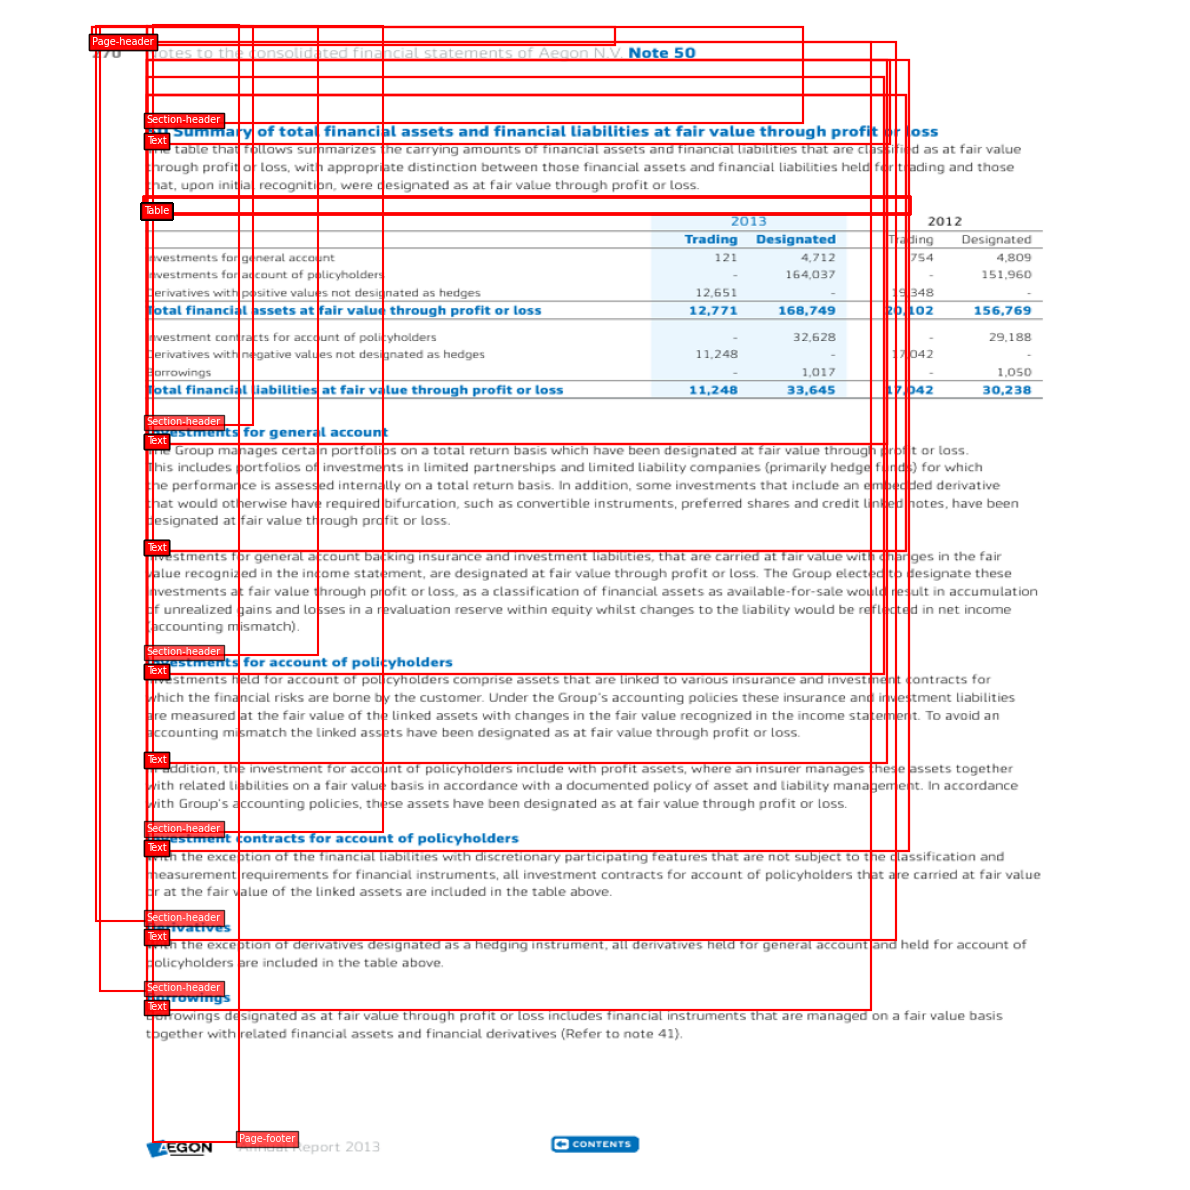

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(16, 12))

ax.imshow(image)

for item in annotation["form"]:

    x_min, y_min, x_max, y_max = item["box"]

    width = x_max - x_min
    height = y_max - y_min

    rect = patches.Rectangle(
        (x_min, y_min),
        width,
        height,
        linewidth=1.5,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x_min,
        y_min,
        item["category"],
        color="white",
        fontsize=7,
        bbox=dict(facecolor="red", alpha=0.7, pad=2)
    )

ax.axis("off")
plt.tight_layout()
plt.show()

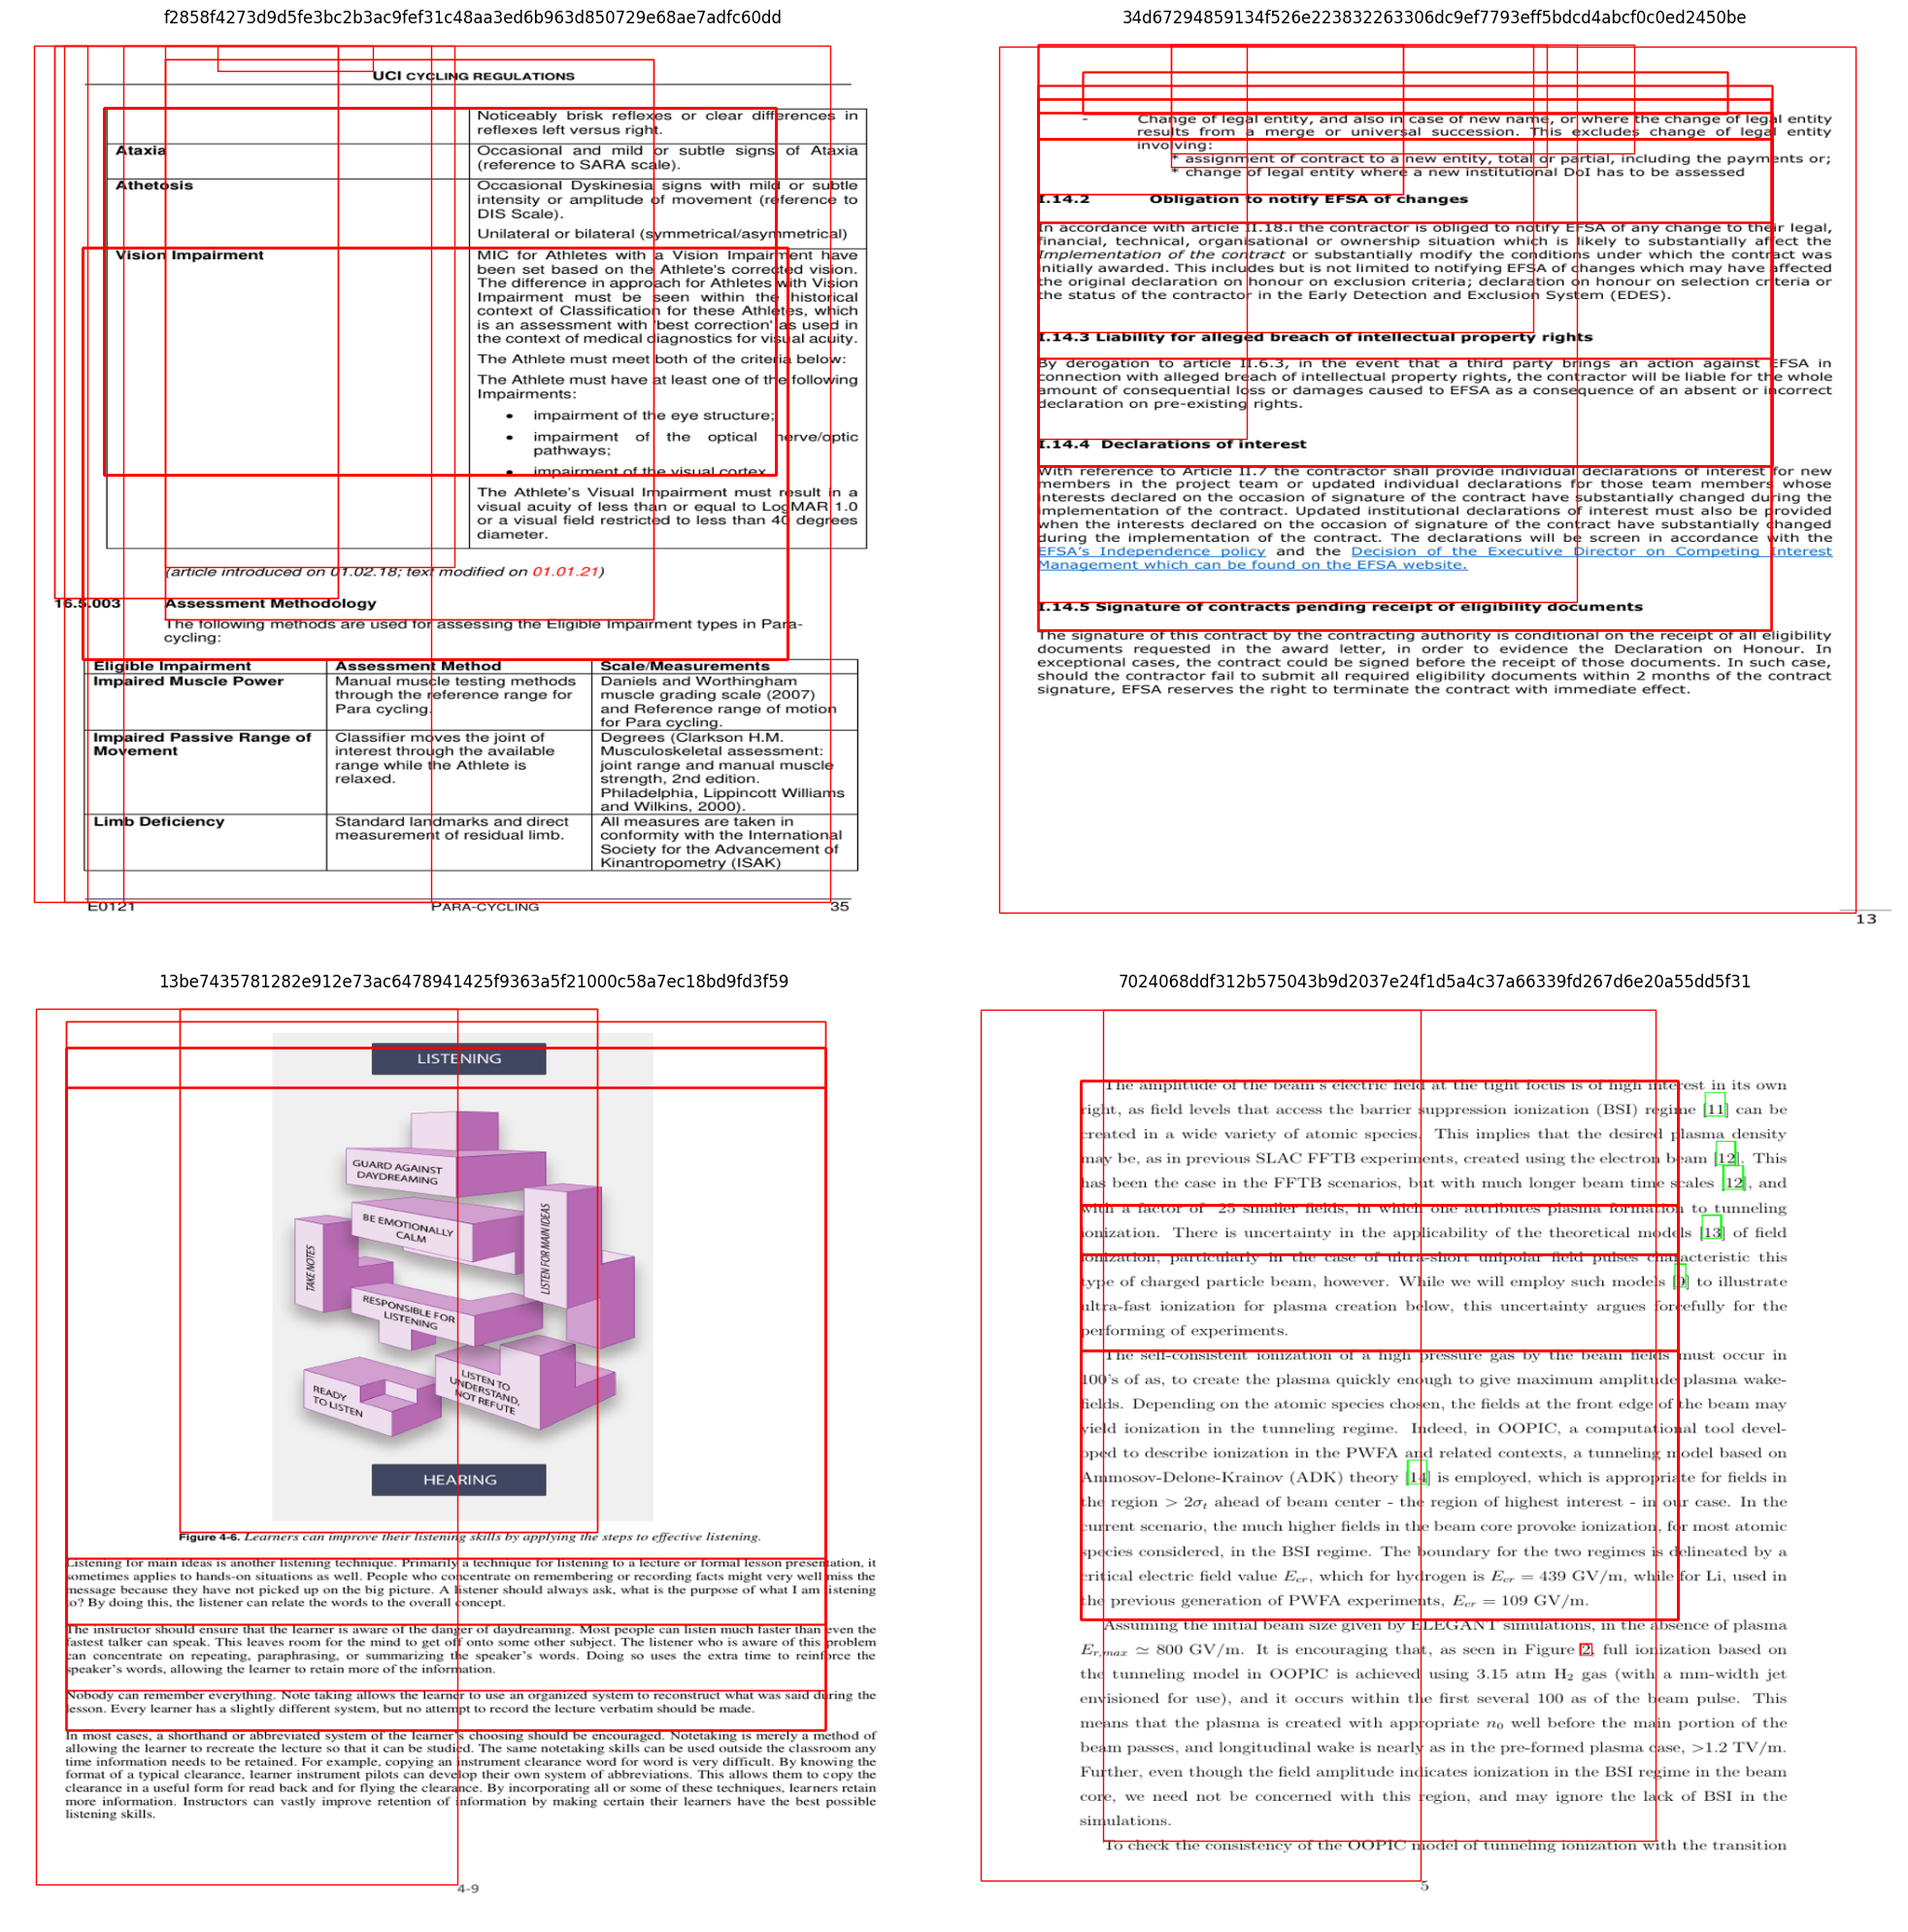

In [ ]:
import random

random.seed(42)

selected_annotations = random.sample(
    annotation_paths,
    min(4, len(annotation_paths))
)

fig, axes = plt.subplots(2, 2, figsize=(20, 20))
axes = axes.flatten()

for ax, path in zip(axes, selected_annotations):

    with open(path, "r", encoding="utf-8") as f:
        ann = json.load(f)

    img_path = IMAGES_DIR / f"{path.stem}.png"
    img = Image.open(img_path).convert("RGB")

    ax.imshow(img)

    for item in ann["form"]:
        x1, y1, x2, y2 = item["box"]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=1,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title(path.stem)
    ax.axis("off")

plt.tight_layout()
plt.show()

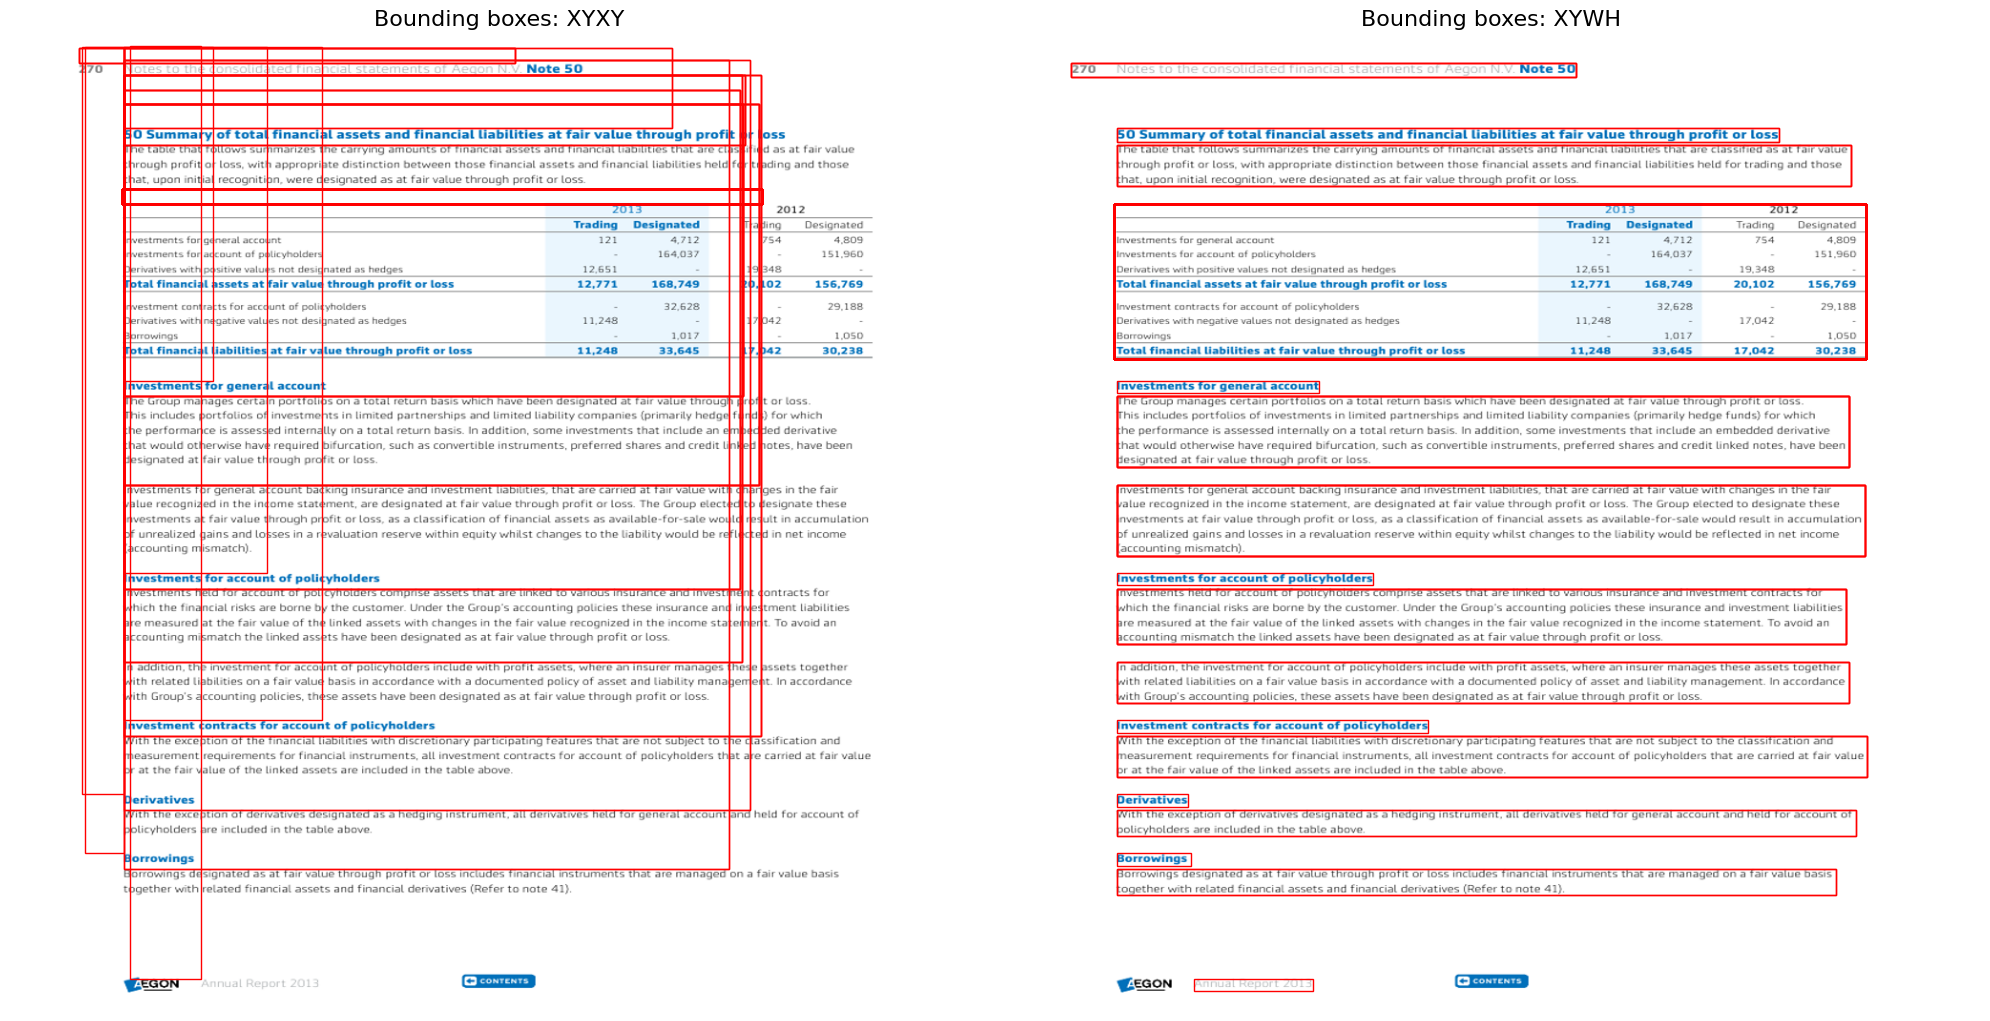

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import json

# Load one sample
annotation_path = annotation_paths[0]

with open(annotation_path, "r") as f:
    annotation = json.load(f)

image_path = IMAGES_DIR / f"{annotation_path.stem}.png"
image = Image.open(image_path).convert("RGB")

fig, axes = plt.subplots(1, 2, figsize=(20, 12))

for ax, mode in zip(axes, ["XYXY", "XYWH"]):

    ax.imshow(image)

    for item in annotation["form"]:

        x, y, a, b = item["box"]

        if mode == "XYXY":
            width = a - x
            height = b - y
        else:
            width = a
            height = b

        rect = patches.Rectangle(
            (x, y),
            width,
            height,
            linewidth=1,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title(f"Bounding boxes: {mode}", fontsize=16)
    ax.axis("off")

plt.tight_layout()
plt.show()

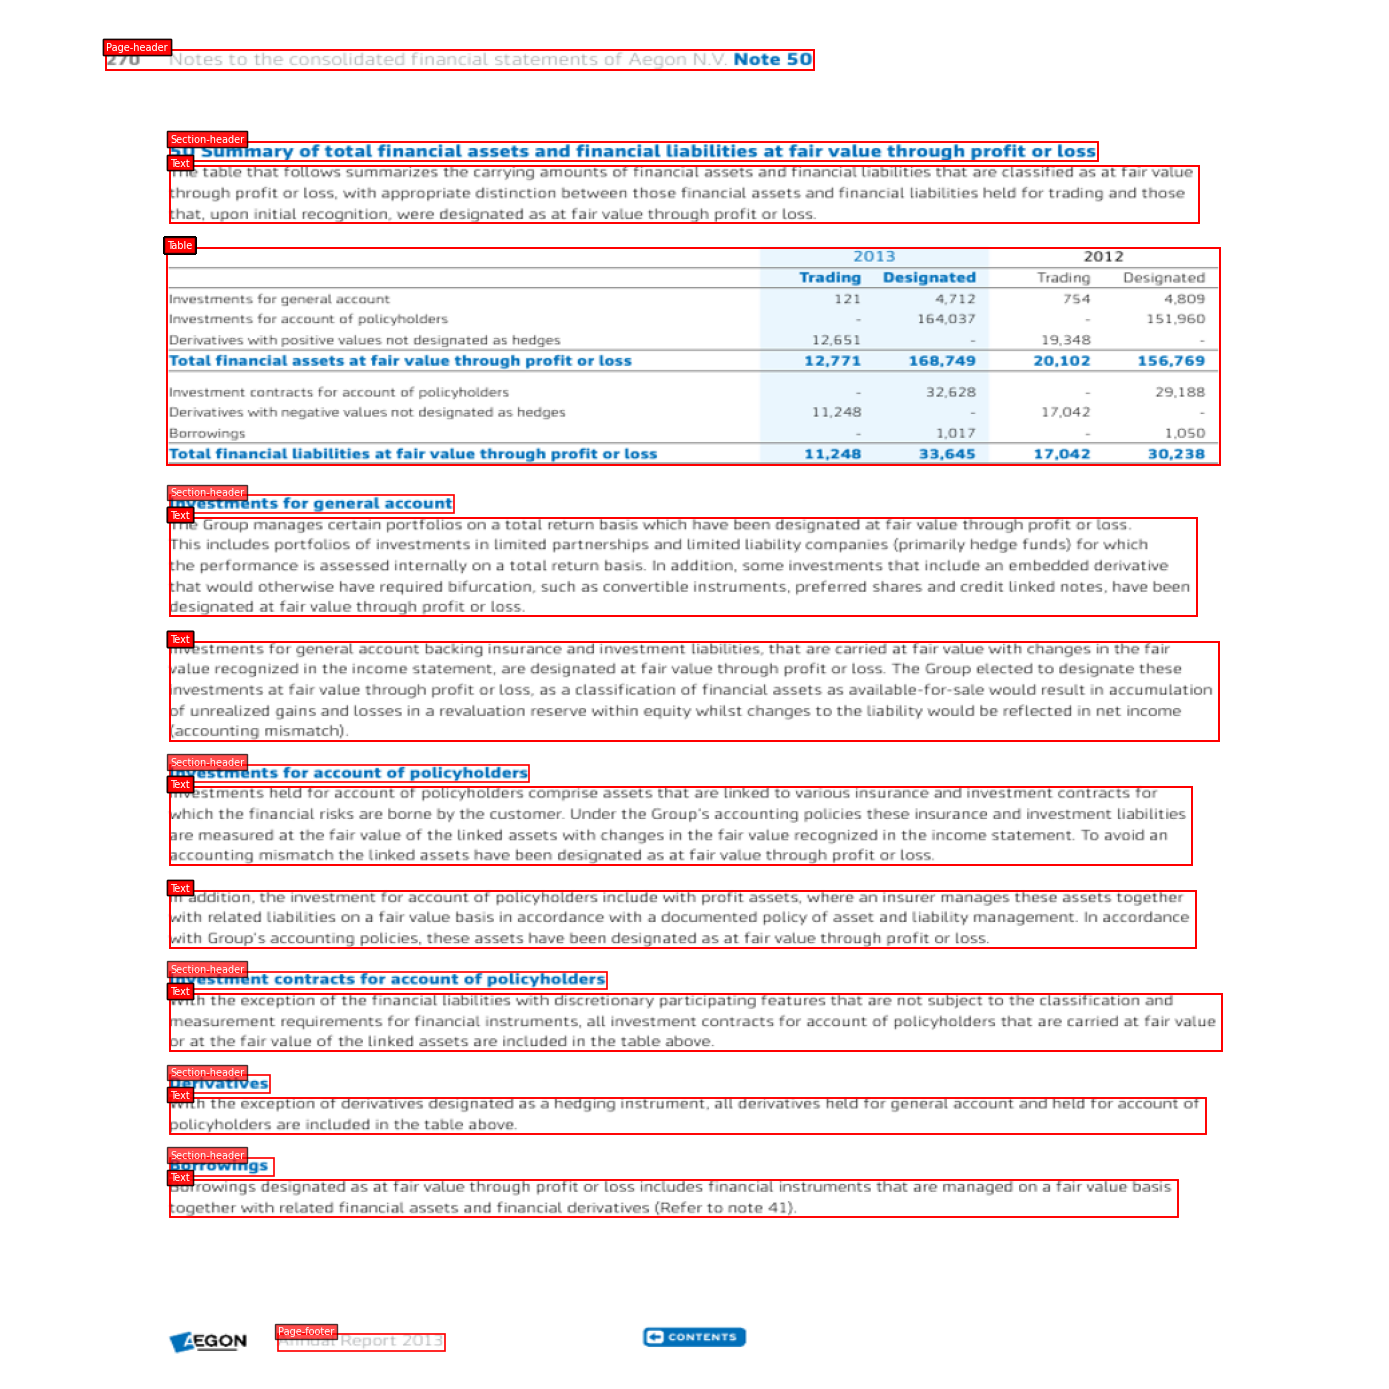

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
import json
import random


def visualize_document(
    annotation_path: Path,
    images_dir: Path,
    show_labels: bool = True,
    figsize: tuple = (14, 18),
):
    """
    Visualize a document page with its block-level bounding boxes.

    Args:
        annotation_path: Path to the JSON annotation.
        images_dir: Directory containing document images.
        show_labels: Whether to display category labels.
        figsize: Matplotlib figure size.
    """

    with open(annotation_path, "r", encoding="utf-8") as f:
        annotation = json.load(f)

    image_path = images_dir / f"{annotation_path.stem}.png"
    image = Image.open(image_path).convert("RGB")

    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(image)

    for item in annotation["form"]:

        x, y, w, h = item["box"]
        category = item["category"]

        rect = patches.Rectangle(
            (x, y),
            w,
            h,
            linewidth=1.2,
            edgecolor="red",
            facecolor="none",
        )

        ax.add_patch(rect)

        if show_labels:
            ax.text(
                x,
                y,
                category,
                color="white",
                fontsize=7,
                bbox={
                    "facecolor": "red",
                    "alpha": 0.7,
                    "pad": 2,
                },
            )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

visualize_document(
    annotation_path=annotation_paths[0],
    images_dir=IMAGES_DIR,
)

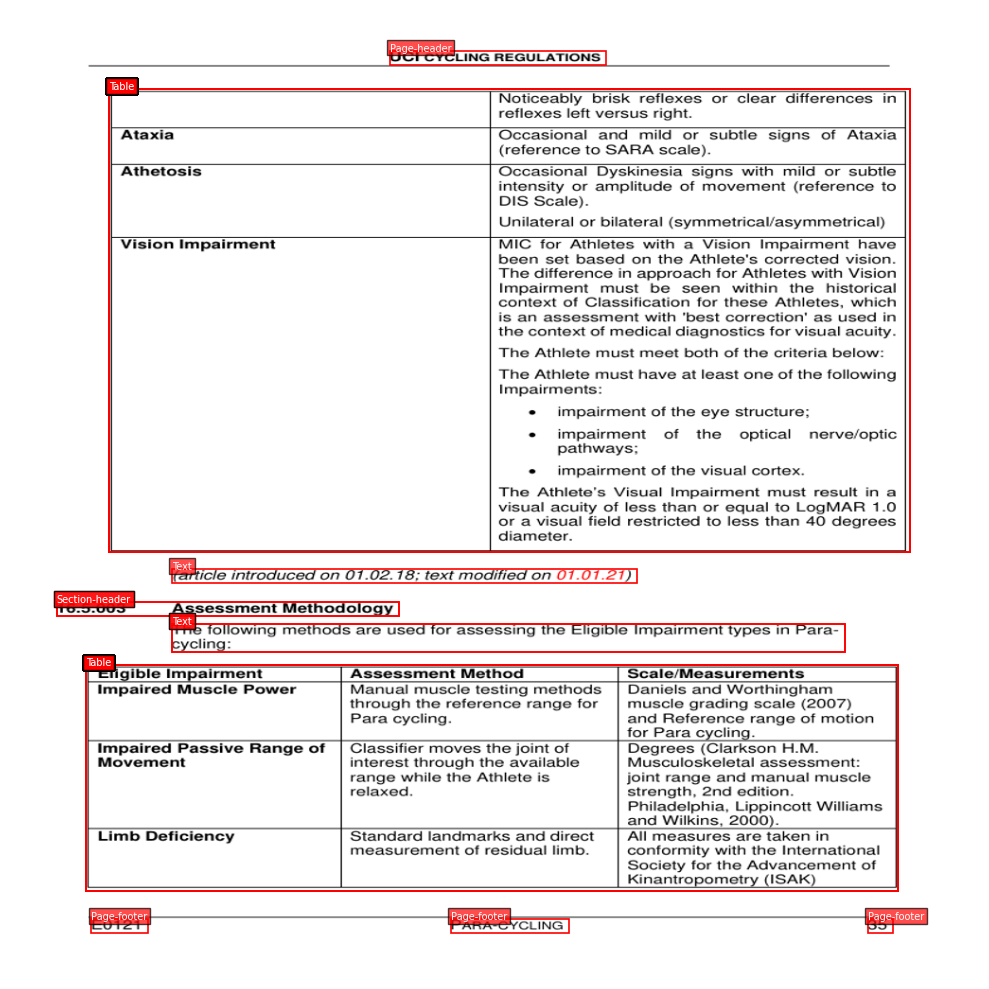

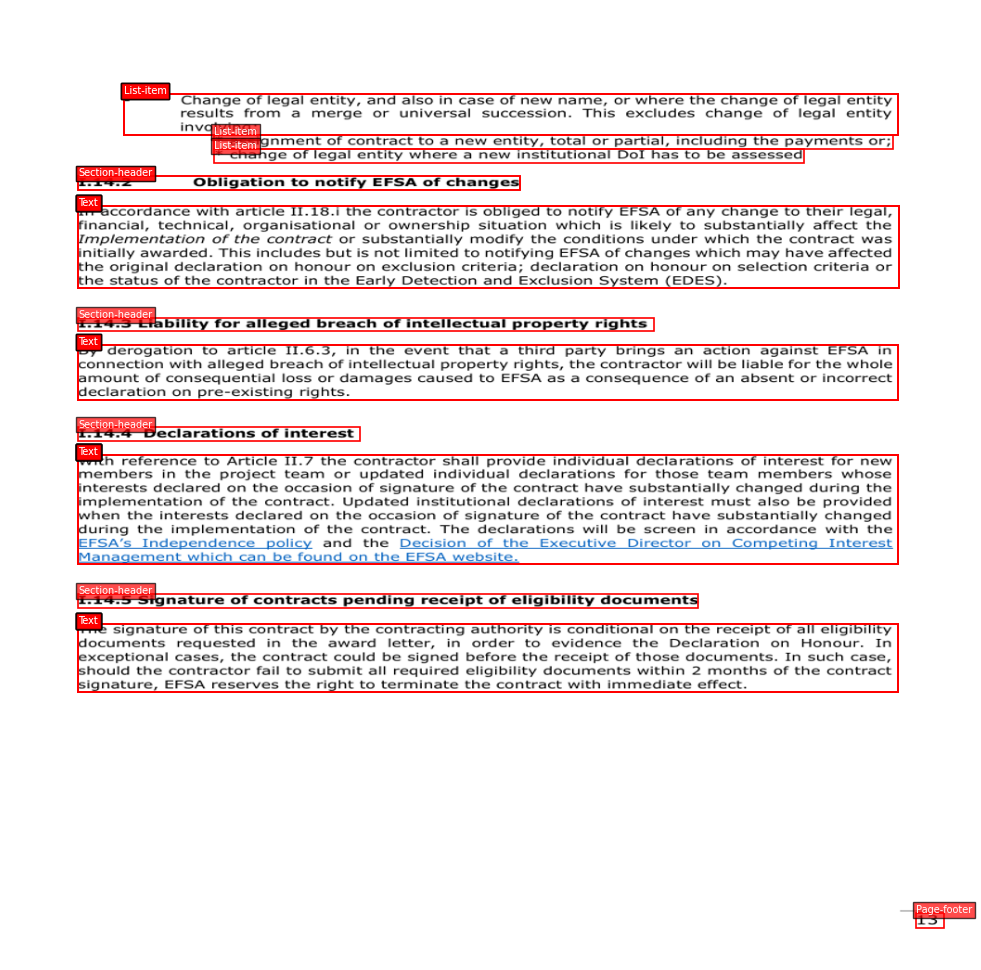

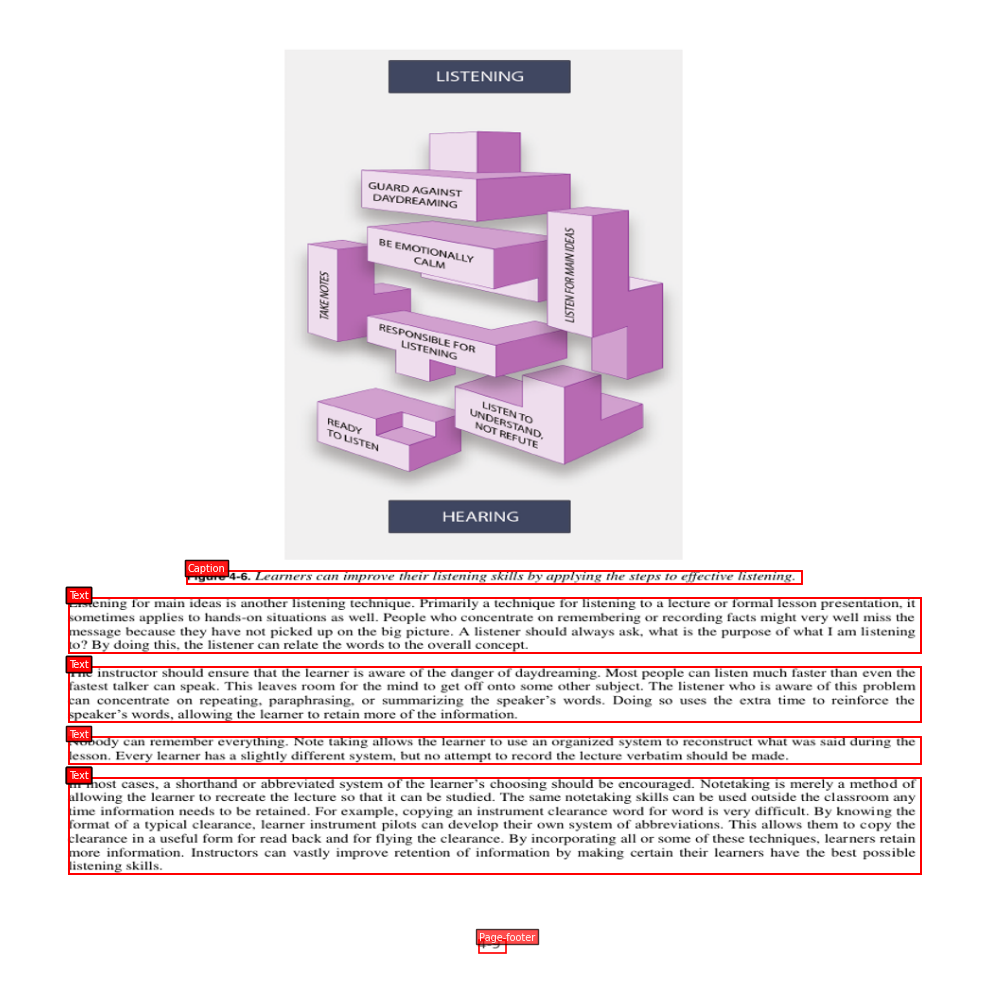

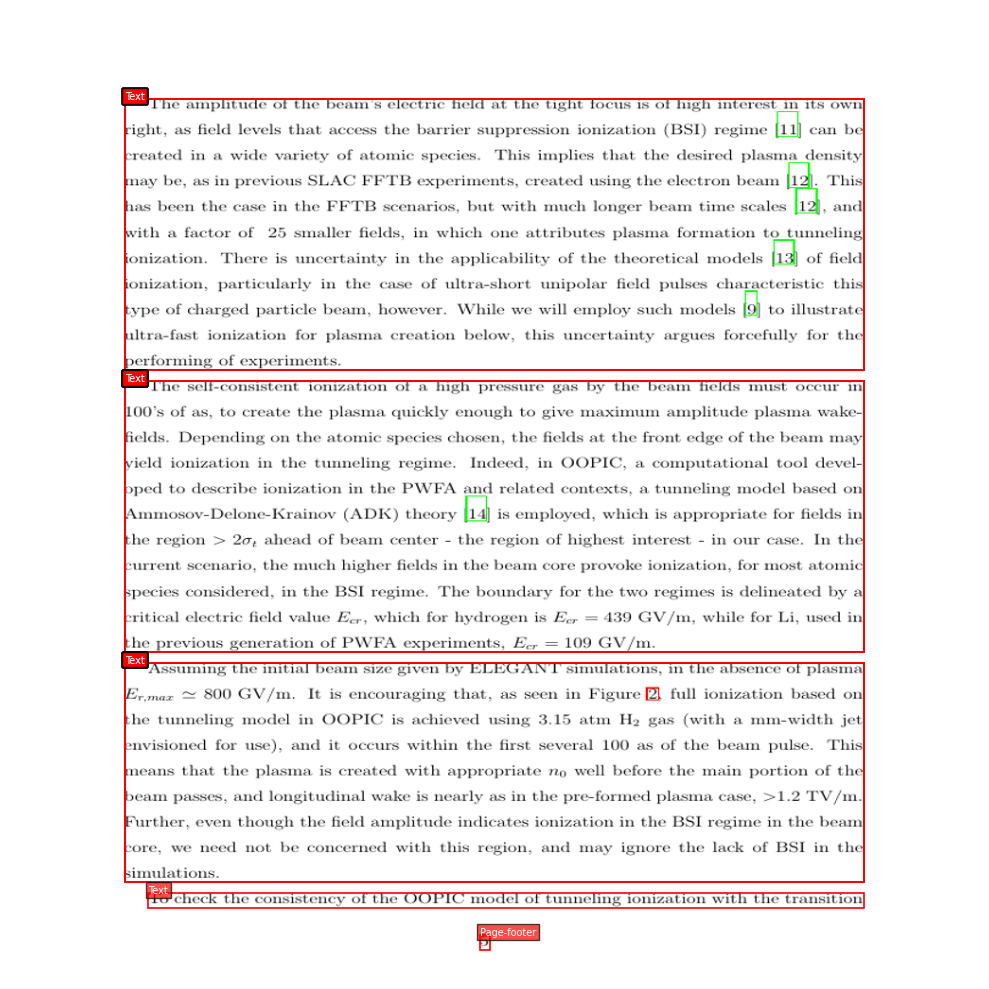

In [ ]:
random.seed(42)

samples = random.sample(
    annotation_paths,
    k=4,
)

for path in samples:
    visualize_document(
        annotation_path=path,
        images_dir=IMAGES_DIR,
        figsize=(10, 12),
    )

In [ ]:
print("Image dimensions:", image.size)

print("\nMetadata:")
for key, value in annotation["metadata"].items():
    print(f"{key}: {value}")

print("\nFirst 5 bounding boxes:")
for item in annotation["form"][:5]:
    print(item["category"], item["box"])

Image dimensions: (1025, 1025)

Metadata:
page_hash: 001be94613c0016cdc1dadc399effb005c7c59ffefca45378bc7b2812c100754
original_filename: NYSE_AEG_2013.pdf
page_no: 270
num_pages: 358
original_width: 609.44897
original_height: 793.70099
coco_width: 1025
coco_height: 1025
collection: ann_reports_10_14_fancy
doc_category: financial_reports

First 5 bounding boxes:
Page-header [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971]
Page-header [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971]
Page-header [71.51146715368145, 30.234517850355815, 529.4478978280987, 14.631782492799971]
Section-header [119.1859400467934, 98.79476715784381, 694.04606155951, 14.618868309588493]
Section-header [119.1859400467934, 98.79476715784381, 694.04606155951, 14.618868309588493]


In [ ]:
CLASS_NAMES = {
    0: "Caption",
    1: "Footnote",
    2: "Formula",
    3: "List-item",
    4: "Page-footer",
    5: "Page-header",
    6: "Picture",
    7: "Section-header",
    8: "Table",
    9: "Text",
    10: "Title",
}

SPLITS = ["train", "val", "test"]

BASE_DIR = DATASET_DIR / "small_dataset"

from collections import Counter
from pathlib import Path
import json
import pandas as pd

class_counts = {
    split: Counter()
    for split in SPLITS
}

image_class_counts = {
    split: Counter()
    for split in SPLITS
}

total_images = {}

for split in SPLITS:

    annotations_dir = BASE_DIR / split / "annotations"
    annotation_files = list(annotations_dir.glob("*.json"))

    total_images[split] = len(annotation_files)

    for annotation_path in annotation_files:

        with open(annotation_path, "r", encoding="utf-8") as f:
            annotation = json.load(f)

        categories_in_image = set()

        for item in annotation["form"]:

            category = item["category"]

            class_counts[split][category] += 1
            categories_in_image.add(category)

        for category in categories_in_image:
            image_class_counts[split][category] += 1

    print(f"{split}: {len(annotation_files)} images")

print("Analysis completed!")

train: 691 images
val: 64 images
test: 49 images
Analysis completed!


In [ ]:
rows = []

for class_id, class_name in CLASS_NAMES.items():

    row = {
        "Class ID": class_id,
        "Class": class_name,
    }

    for split in SPLITS:
        row[split] = class_counts[split][class_name]

    row["Total"] = sum(
        row[split]
        for split in SPLITS
    )

    rows.append(row)

df = pd.DataFrame(rows)

display(df)

,Class ID,Class,train,val,test,Total
0,0,Caption,1963,34,25,2022
1,1,Footnote,113,43,0,156
2,2,Formula,5482,394,255,6131
3,3,List-item,6611,519,379,7509
4,4,Page-footer,792,64,58,914
5,5,Page-header,658,110,47,815
6,6,Picture,3848,273,114,4235
7,7,Section-header,1830,327,85,2242
8,8,Table,11633,1503,1905,15041
9,9,Text,33657,3004,1703,38364


In [ ]:
df["Percentage"] = (
    df["Total"] / df["Total"].sum() * 100
).round(2)

display(
    df[["Class", "Total", "Percentage"]]
    .sort_values("Total", ascending=False)
)

,Class,Total,Percentage
9,Text,38364,49.42
8,Table,15041,19.38
3,List-item,7509,9.67
2,Formula,6131,7.90
6,Picture,4235,5.46
7,Section-header,2242,2.89
0,Caption,2022,2.60
4,Page-footer,914,1.18
5,Page-header,815,1.05
10,Title,193,0.25


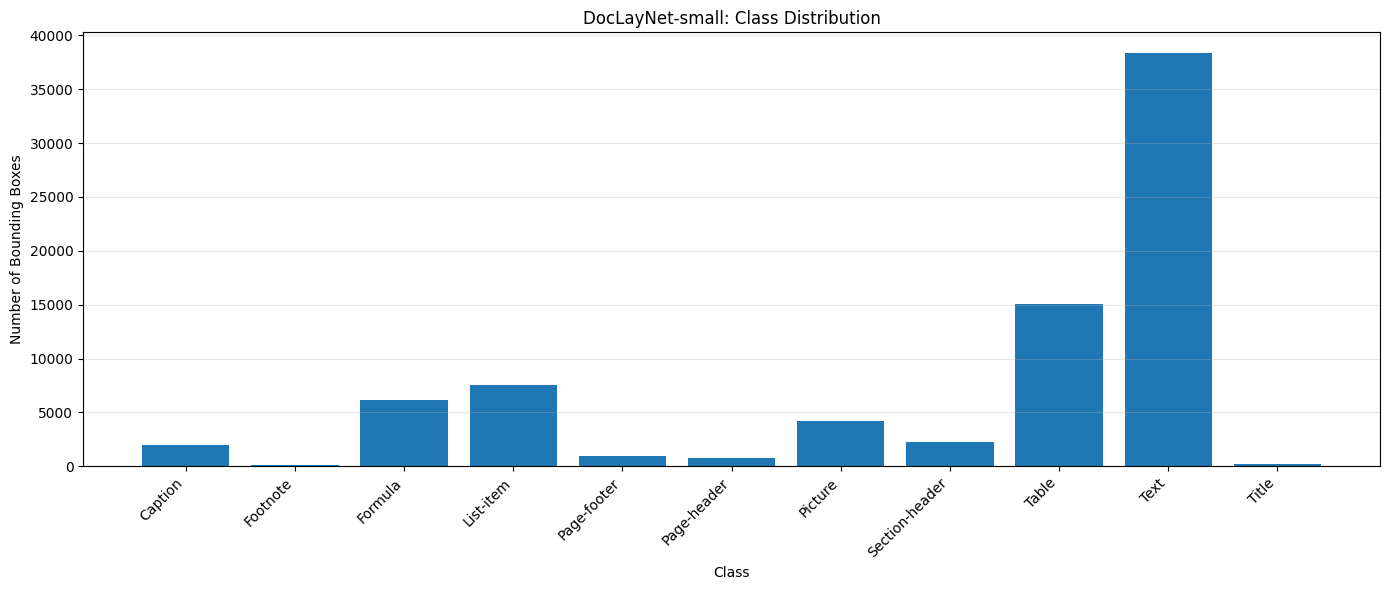

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(
    df["Class"],
    df["Total"],
)

plt.title("DocLayNet-small: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Bounding Boxes")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

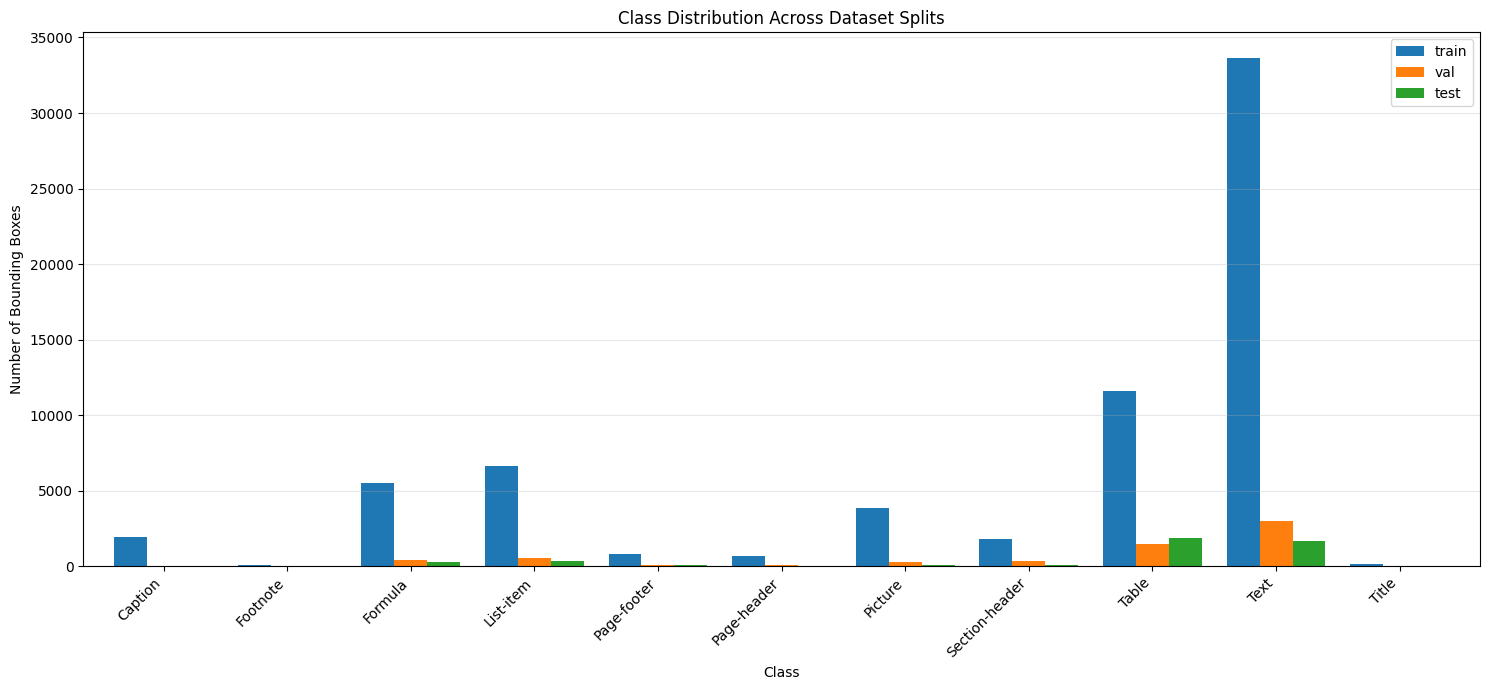

In [ ]:
split_df = df.set_index("Class")[SPLITS]

split_df.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8,
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Class")
plt.ylabel("Number of Bounding Boxes")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
image_df = pd.DataFrame(
    {
        split: {
            class_name: image_class_counts[split][class_name]
            for class_name in CLASS_NAMES.values()
        }
        for split in SPLITS
    }
)

image_df.index.name = "Class"

display(image_df)

,train,val,test
Class,,,
Caption,136,8,8
Footnote,16,4,0
Formula,57,6,3
List-item,209,10,14
Page-footer,519,47,36
Page-header,322,40,22
Picture,114,9,5
Section-header,441,47,27
Table,163,13,20


In [ ]:
image_percentage_df = image_df.copy()

for split in SPLITS:
    image_percentage_df[split] = (
        image_df[split] / total_images[split] * 100
    ).round(2)

display(image_percentage_df)

,train,val,test
Class,,,
Caption,19.68,12.50,16.33
Footnote,2.32,6.25,0.00
Formula,8.25,9.38,6.12
List-item,30.25,15.62,28.57
Page-footer,75.11,73.44,73.47
Page-header,46.60,62.50,44.90
Picture,16.50,14.06,10.20
Section-header,63.82,73.44,55.10
Table,23.59,20.31,40.82


In [ ]:
from pathlib import Path

# Original dataset
SOURCE_DIR = DATASET_DIR / "small_dataset"

# Converted YOLO dataset
YOLO_DIR = DATASET_DIR.parent / "DocLayNet-YOLO"

SPLITS = ["train", "val", "test"]

CLASS_NAMES = {
    0: "Caption",
    1: "Footnote",
    2: "Formula",
    3: "List-item",
    4: "Page-footer",
    5: "Page-header",
    6: "Picture",
    7: "Section-header",
    8: "Table",
    9: "Text",
    10: "Title",
}

# Reverse mapping: category name -> YOLO class ID
CLASS_TO_ID = {
    name: class_id
    for class_id, name in CLASS_NAMES.items()
}

# Create output directories
for split in SPLITS:
    (YOLO_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (YOLO_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

print("YOLO directories created!")
print("Output:", YOLO_DIR)

YOLO directories created!
Output: /content/drive/MyDrive/datasets/DocLayNet-YOLO


In [ ]:
def convert_bbox_to_yolo(
    bbox: list,
    image_width: int,
    image_height: int,
) -> tuple[float, float, float, float]:
    """
    Convert a pixel-based XYWH bounding box to normalized YOLO format.

    Args:
        bbox: [x_min, y_min, width, height].
        image_width: Image width in pixels.
        image_height: Image height in pixels.

    Returns:
        (x_center, y_center, width, height), normalized to [0, 1].
    """

    x, y, w, h = map(float, bbox)

    x_center = (x + w / 2) / image_width
    y_center = (y + h / 2) / image_height

    normalized_width = w / image_width
    normalized_height = h / image_height

    return (
        x_center,
        y_center,
        normalized_width,
        normalized_height,
    )

In [ ]:
import json
import math


def convert_annotation(
    annotation_path: Path,
    image_width: int,
    image_height: int,
) -> list[str]:

    with open(annotation_path, "r", encoding="utf-8") as f:
        annotation = json.load(f)

    yolo_labels = []

    for item in annotation["form"]:

        category = item["category"]

        if category not in CLASS_TO_ID:
            raise ValueError(f"Unknown category: {category}")

        class_id = CLASS_TO_ID[category]

        x, y, w, h = map(float, item["box"])

        # Check for invalid numerical values
        if not all(math.isfinite(v) for v in (x, y, w, h)):
            continue

        if w <= 0 or h <= 0:
            continue

        # Original bottom-right coordinates
        x2 = x + w
        y2 = y + h

        # Clip bounding box to image boundaries
        x1 = max(0.0, x)
        y1 = max(0.0, y)

        x2 = min(float(image_width), x2)
        y2 = min(float(image_height), y2)

        # Skip boxes completely outside the image
        if x2 <= x1 or y2 <= y1:
            continue

        # Recalculate XYWH after clipping
        clipped_w = x2 - x1
        clipped_h = y2 - y1

        # Convert to normalized YOLO coordinates
        x_center = (x1 + clipped_w / 2) / image_width
        y_center = (y1 + clipped_h / 2) / image_height

        normalized_w = clipped_w / image_width
        normalized_h = clipped_h / image_height

        yolo_labels.append(
            f"{class_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{normalized_w:.6f} "
            f"{normalized_h:.6f}"
        )

    return yolo_labels

In [ ]:
import shutil
from PIL import Image


def convert_split(split: str):
    """
    Convert one DocLayNet split into YOLO format.
    """

    source_images = SOURCE_DIR / split / "images"
    source_annotations = SOURCE_DIR / split / "annotations"

    output_images = YOLO_DIR / "images" / split
    output_labels = YOLO_DIR / "labels" / split

    annotation_paths = sorted(
        source_annotations.glob("*.json")
    )

    total_objects = 0
    total_images = 0

    for annotation_path in annotation_paths:

        # Find the corresponding image
        image_path = None

        for extension in [".png", ".jpg", ".jpeg"]:
            candidate = (
                source_images /
                f"{annotation_path.stem}{extension}"
            )

            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            raise FileNotFoundError(
                f"Image not found for {annotation_path.name}"
            )

        # Read image dimensions
        with Image.open(image_path) as image:
            image_width, image_height = image.size

        # Convert annotations
        labels = convert_annotation(
            annotation_path=annotation_path,
            image_width=image_width,
            image_height=image_height,
        )

        # Copy image
        shutil.copy2(
            image_path,
            output_images / image_path.name,
        )

        # Save YOLO labels
        label_path = (
            output_labels /
            f"{annotation_path.stem}.txt"
        )

        with open(label_path, "w", encoding="utf-8") as f:
            f.write("\n".join(labels))

        total_images += 1
        total_objects += len(labels)

    print(
        f"{split}: "
        f"{total_images} images, "
        f"{total_objects} objects"
    )


# Convert all splits
for split in SPLITS:
    convert_split(split)

print("\nDataset conversion completed!")

train: 691 images, 66734 objects
val: 64 images, 6282 objects
test: 49 images, 4606 objects

Dataset conversion completed!


In [ ]:
yaml_content = f"""
path: {YOLO_DIR.resolve()}

train: images/train
val: images/val
test: images/test

nc: {len(CLASS_NAMES)}

names:
"""

for class_id, class_name in CLASS_NAMES.items():
    yaml_content += f"  {class_id}: {class_name}\n"

yaml_path = YOLO_DIR / "data.yaml"

with open(yaml_path, "w", encoding="utf-8") as f:
    f.write(yaml_content.strip() + "\n")

print(yaml_content)


path: /content/drive/MyDrive/datasets/DocLayNet-YOLO

train: images/train
val: images/val
test: images/test

nc: 11

names:
  0: Caption
  1: Footnote
  2: Formula
  3: List-item
  4: Page-footer
  5: Page-header
  6: Picture
  7: Section-header
  8: Table
  9: Text
  10: Title



In [ ]:
def validate_yolo_labels(labels_dir: Path):

    invalid_labels = []

    for label_path in labels_dir.glob("*.txt"):

        with open(label_path, "r") as f:

            for line_number, line in enumerate(f, start=1):

                values = line.split()

                if len(values) != 5:
                    invalid_labels.append(
                        (label_path.name, line_number, "Invalid format")
                    )
                    continue

                class_id, xc, yc, w, h = map(float, values)

                if not (
                    0 <= class_id < len(CLASS_NAMES)
                    and 0 <= xc <= 1
                    and 0 <= yc <= 1
                    and 0 < w <= 1
                    and 0 < h <= 1
                ):
                    invalid_labels.append(
                        (label_path.name, line_number, values)
                    )

    return invalid_labels

In [ ]:
for split in SPLITS:

    labels_dir = YOLO_DIR / "labels" / split

    invalid = validate_yolo_labels(labels_dir)

    print(
        f"{split}: "
        f"{len(invalid)} invalid annotations"
    )

    if invalid:
        print(invalid[:5])

train: 0 invalid annotations
val: 0 invalid annotations
test: 0 invalid annotations


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path


def draw_yolo_boxes(
    ax,
    image,
    label_path: Path,
    class_names: dict,
    color: str = "red",
):
    """
    Draw YOLO bounding boxes on an image.

    Args:
        ax: Matplotlib axis.
        image: PIL image.
        label_path: Path to YOLO .txt annotation.
        class_names: Mapping of class IDs to class names.
        color: Bounding box color.
    """

    image_width, image_height = image.size

    ax.imshow(image)

    with open(label_path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    for line in lines:

        values = line.strip().split()

        if len(values) != 5:
            continue

        class_id, xc, yc, w, h = map(float, values)

        # Convert normalized coordinates to pixels
        x_center = xc * image_width
        y_center = yc * image_height

        box_width = w * image_width
        box_height = h * image_height

        x1 = x_center - box_width / 2
        y1 = y_center - box_height / 2

        rect = patches.Rectangle(
            (x1, y1),
            box_width,
            box_height,
            linewidth=1,
            edgecolor=color,
            facecolor="none",
        )

        ax.add_patch(rect)

        category = class_names[int(class_id)]

        ax.text(
            x1,
            y1,
            category,
            color="white",
            fontsize=7,
            bbox={
                "facecolor": color,
                "alpha": 0.7,
                "pad": 2,
            },
        )

    ax.axis("off")

In [ ]:
import json


def visualize_comparison(
    annotation_path: Path,
    split: str,
):
    """
    Compare original DocLayNet annotations
    against converted YOLO annotations.
    """

    # Original paths
    original_images_dir = SOURCE_DIR / split / "images"

    # YOLO paths
    yolo_images_dir = YOLO_DIR / "images" / split
    yolo_labels_dir = YOLO_DIR / "labels" / split

    # Load original annotation
    with open(annotation_path, "r", encoding="utf-8") as f:
        annotation = json.load(f)

    # Locate image
    image_path = next(
        (
            original_images_dir / f"{annotation_path.stem}{ext}"
            for ext in [".png", ".jpg", ".jpeg"]
            if (original_images_dir / f"{annotation_path.stem}{ext}").exists()
        ),
        None,
    )

    if image_path is None:
        raise FileNotFoundError(annotation_path.stem)

    image = Image.open(image_path).convert("RGB")

    # YOLO label
    label_path = yolo_labels_dir / f"{annotation_path.stem}.txt"

    fig, axes = plt.subplots(1, 2, figsize=(20, 14))

    # Original annotations
    axes[0].imshow(image)

    for item in annotation["form"]:

        x, y, w, h = map(float, item["box"])

        # Clip original boxes just like our conversion
        x1 = max(0.0, x)
        y1 = max(0.0, y)
        x2 = min(float(image.width), x + w)
        y2 = min(float(image.height), y + h)

        if x2 <= x1 or y2 <= y1:
            continue

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=1,
            edgecolor="red",
            facecolor="none",
        )

        axes[0].add_patch(rect)

        axes[0].text(
            x1,
            y1,
            item["category"],
            color="white",
            fontsize=7,
            bbox=dict(facecolor="red", alpha=0.7, pad=2),
        )

    axes[0].set_title("Original DocLayNet annotations")
    axes[0].axis("off")

    # Converted YOLO annotations
    draw_yolo_boxes(
        ax=axes[1],
        image=image,
        label_path=label_path,
        class_names=CLASS_NAMES,
    )

    axes[1].set_title("Converted YOLO annotations")

    plt.tight_layout()
    plt.show()

    print("Image:", annotation_path.stem)
    print("Original objects:", len(annotation["form"]))

    with open(label_path, "r") as f:
        print("YOLO objects:", len(f.readlines()))

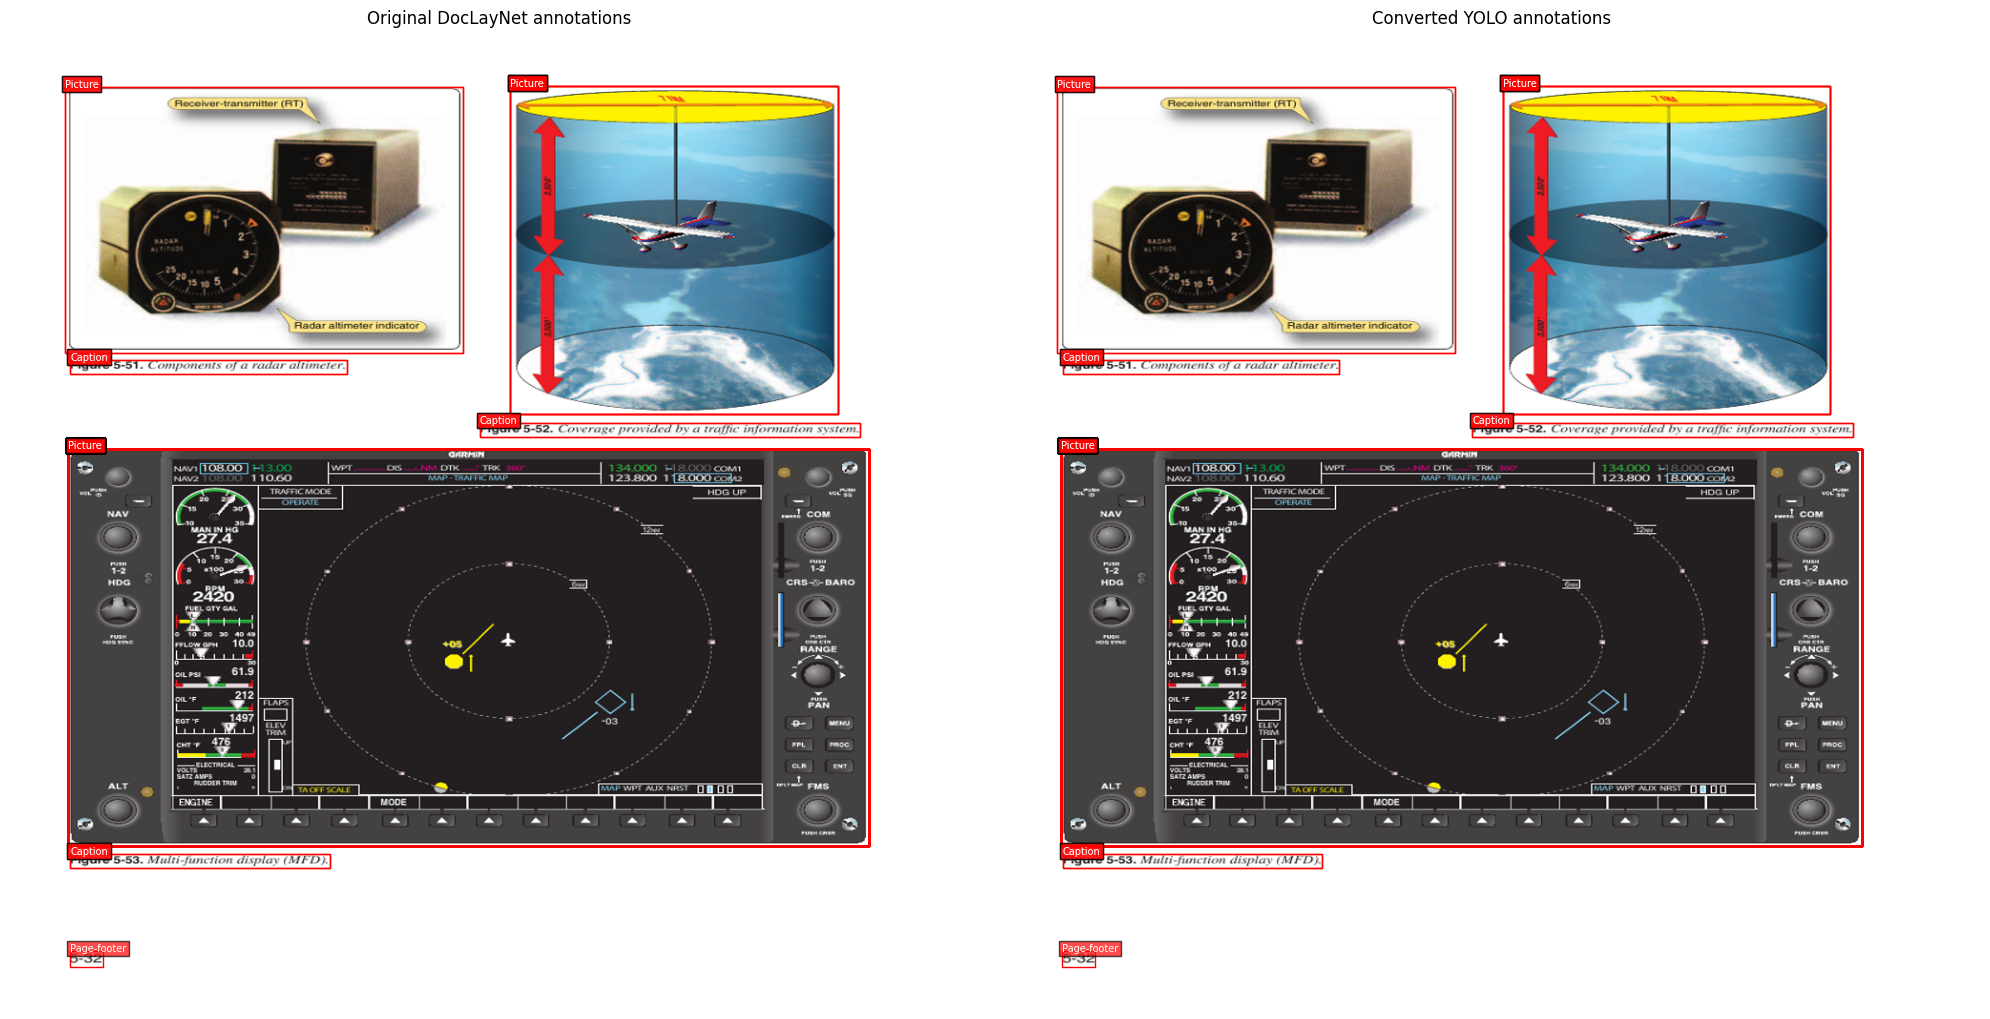

Image: a2efa1cd4781d45b0dd47a122ed37b0e1cad0c113b9c0b3814f2fa1ec51e38bc
Original objects: 56
YOLO objects: 56


In [ ]:
import random

random.seed()

annotation_path = random.choice(annotation_paths)

visualize_comparison(
    annotation_path=annotation_path,
    split="train",
)

In [ ]:
for split in SPLITS:

    original_count = 0
    converted_count = 0

    original_dir = SOURCE_DIR / split / "annotations"
    converted_dir = YOLO_DIR / "labels" / split

    for path in original_dir.glob("*.json"):

        with open(path, "r") as f:
            annotation = json.load(f)

        original_count += len(annotation["form"])

    for path in converted_dir.glob("*.txt"):

        with open(path, "r") as f:
            converted_count += len(f.readlines())

    print(f"\n{split.upper()}")
    print("Original objects:", original_count)
    print("Converted objects:", converted_count)
    print("Removed objects:", original_count - converted_count)


TRAIN
Original objects: 66734
Converted objects: 66734
Removed objects: 0

VAL
Original objects: 6282
Converted objects: 6282
Removed objects: 0

TEST
Original objects: 4606
Converted objects: 4606
Removed objects: 0


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu
CUDA available: False


In [ ]:
!pip install -q ultralytics

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import torch
import yaml


YOLO_DIR = Path(
    "/content/drive/MyDrive/datasets/DocLayNet-YOLO"
)

DATA_YAML = YOLO_DIR / "data.yaml"

with open(DATA_YAML, "r") as f:
    config = yaml.safe_load(f)

print(config)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
{'path': '/content/drive/MyDrive/datasets/DocLayNet-YOLO', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'nc': 11, 'names': {0: 'Caption', 1: 'Footnote', 2: 'Formula', 3: 'List-item', 4: 'Page-footer', 5: 'Page-header', 6: 'Picture', 7: 'Section-header', 8: 'Table', 9: 'Text', 10: 'Title'}}


In [ ]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset(str(DATA_YAML))

print("Dataset verified!")
print("Classes:", data["names"])
print("Number of classes:", data["nc"])

Dataset verified!
Classes: {0: 'Caption', 1: 'Footnote', 2: 'Formula', 3: 'List-item', 4: 'Page-footer', 5: 'Page-header', 6: 'Picture', 7: 'Section-header', 8: 'Table', 9: 'Text', 10: 'Title'}
Number of classes: 11


In [ ]:
from pathlib import Path
from ultralytics import YOLO

# Initialize pretrained YOLO11 nano
model = YOLO("yolo11n.pt")

# Training output
RUN_DIR = Path("/content/runs/doclaynet")

results = model.train(
    data=str(DATA_YAML),

    epochs=4,
    imgsz=1024,
    batch=4,

    # device=0,
    workers=2,

    pretrained=True,
    patience=20,

    amp=True,
    plots=True,

    project=str(RUN_DIR),
    name="yolo11n_baseline",

    exist_ok=True,
    seed=42,
    deterministic=True,
)

Ultralytics 8.4.201 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/datasets/DocLayNet-YOLO/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_baseline, nbs=64, nms=None

In [ ]:
# Next time, mount Drive and load it again using the same cache directory:
# from google.colab import drive
# from datasets import load_dataset
# from pathlib import Path

# drive.mount('/content/drive')

# DATASET_DIR = Path(
#     "/content/drive/MyDrive/datasets/DocLayNet-small"
# )

# dataset = load_dataset(
#     "pierreguillou/DocLayNet-small",
#     trust_remote_code=True,
#     cache_dir=str(DATASET_DIR / "cache")
# )